# 3.4.4 Flow reversal: co-current and counter-current regeneration against equilibrium theory

Reads the runs written by `generate.py` and executed by `run.py`. A trace adsorbate A ($y_\mathrm{F} = 10^{-3}$ in
helium, Langmuir isotherm with $b\,p_\mathrm{F} = 4$) loads a clean column until its shock front has crossed about half
the column; the column is then purged with helium, co-currently (purge at $z = 0$) or counter-currently (purge at
$z = L$, `FlowDirection` `Reverse`). With a constant velocity (trace limit, `FixedVelocity`), fast mass transfer, and no
axial dispersion, the column follows the equilibrium theory of Rhee, Aris, and Amundson (README.md):

- loading: a shock at $w_s = v / (1 + F q^*(c_\mathrm{F})/c_\mathrm{F})$, $F = (1-\varepsilon)\rho_p/\varepsilon$;
- purge: a centred desorption wave with the characteristic speeds $w(c) = v / (1 + F\,\mathrm{d}q^*/\mathrm{d}c)$, from the
  front back to $z = 0$ (counter-current), or from $z = 0$ forward, where it overtakes the shock before the outlet
  (co-current; the weakened shock follows $\mathrm{d}z_s/\mathrm{d}t = v/(1 + F q^*(c_l)/c_l)$ with $c_l$ from the wave).

Time is given as $t/t_\mathrm{st}$, with the stoichiometric time $t_\mathrm{st} = L/w_s$ of the loading front. The paper
panels are written to `ruptura-2.0-paper/figures/flow_reversal/`.

In [1]:
import json
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "simulations" / "index.json").is_file():
    raise FileNotFoundError("Run this notebook from validation/3.4.4_flow_reversal after generate.py and run.py.")
REPOSITORY = ROOT.parent.parent
FIGURE_DIR = REPOSITORY / "ruptura-2.0-paper" / "figures" / "flow_reversal"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

INDEX = json.loads((ROOT / "simulations" / "index.json").read_text())
PARAMETERS = INDEX["parameters"]
RUNS = pd.DataFrame(INDEX["runs"])
SHOWN_SCHEME = "WENO3"
SHOWN_GRID_POINTS = 100  # the default grid of the validation cases
PROFILE_TIMES = (0.0, 0.1, 0.5, 1.5)  # t/t_st after the start of the purge

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 10,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "legend.handlelength": 1.6,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

## Equilibrium theory

In [2]:
R = 8.31446261815324  # J/(mol K), src/utils.h

VELOCITY = PARAMETERS["velocity_m_per_s"]
LENGTH = PARAMETERS["length_m"]
CAPACITY_RATIO = (1.0 - PARAMETERS["void_fraction"]) * PARAMETERS["particle_density_kg_per_m3"] / PARAMETERS["void_fraction"]
AFFINITY = PARAMETERS["affinity_per_Pa"] * R * PARAMETERS["temperature_K"]  # K = b R T, m3/mol
SATURATION = PARAMETERS["saturation_loading_mol_per_kg"]
FEED = PARAMETERS["feed_mole_fraction"] * PARAMETERS["pressure_Pa"] / (R * PARAMETERS["temperature_K"])  # c_F, mol/m3
LOADING_TIME = PARAMETERS["loading_duration_s"]


def loading(c):
    return SATURATION * AFFINITY * c / (1.0 + AFFINITY * c)


def wave_speed(c):
    # w(c) = v / (1 + F dq*/dc) of the Langmuir isotherm
    return VELOCITY / (1.0 + CAPACITY_RATIO * SATURATION * AFFINITY / (1.0 + AFFINITY * c) ** 2)


def concentration_of_speed(speed):
    # Inverse of wave_speed between w(0) and w(c_F)
    ratio = CAPACITY_RATIO * SATURATION * AFFINITY / np.maximum(VELOCITY / np.asarray(speed, dtype=float) - 1.0, 1e-300)
    return np.clip((np.sqrt(ratio) - 1.0) / AFFINITY, 0.0, FEED)


SHOCK_SPEED = VELOCITY / (1.0 + CAPACITY_RATIO * loading(FEED) / FEED)
STOICHIOMETRIC_TIME = LENGTH / SHOCK_SPEED
FRONT = SHOCK_SPEED * LOADING_TIME  # shock position at the end of loading, m
# Co-current: the fastest characteristic of the desorption wave from z = 0 overtakes the shock at t*.
CATCH_UP_TIME = FRONT / (wave_speed(FEED) - SHOCK_SPEED)


@lru_cache(maxsize=None)
def co_current_shock_path():
    # Shock position after t*, from dz/dt = v / (1 + F q*(c_l)/c_l), c_l = c(z/t) of the wave, by RK4 in steps of 1e-4 t
    # until the shock leaves the column; returns (times, positions).
    def speed(time, position):
        left = concentration_of_speed(position / time)
        return VELOCITY / (1.0 + CAPACITY_RATIO * loading(left) / max(float(left), 1e-300))

    times = [CATCH_UP_TIME]
    positions = [wave_speed(FEED) * CATCH_UP_TIME]
    while positions[-1] < LENGTH:
        time, position = times[-1], positions[-1]
        step = 1.0e-4 * time
        k1 = speed(time, position)
        k2 = speed(time + 0.5 * step, position + 0.5 * step * k1)
        k3 = speed(time + 0.5 * step, position + 0.5 * step * k2)
        k4 = speed(time + step, position + step * k3)
        times.append(time + step)
        positions.append(position + step * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0)
    return np.array(times), np.array(positions)


def shock_position(time):
    times, positions = co_current_shock_path()
    return np.where(time <= CATCH_UP_TIME, FRONT + SHOCK_SPEED * time, np.interp(time, times, positions, right=np.inf))


def theory_profile(direction, position, time):
    # c(z, t) after the start of the purge (time >= 0), mol/m3
    position = np.asarray(position, dtype=float)
    if time <= 0.0:
        return np.where(position < FRONT, FEED, 0.0)
    if direction == "counter-current":
        # the wave is centred at the front and moves towards z = 0
        distance = FRONT - position
        profile = np.where(distance >= wave_speed(FEED) * time, FEED, concentration_of_speed(np.maximum(distance, 1e-300) / time))
        return np.where(distance <= wave_speed(0.0) * time, 0.0, profile)
    # co-current: the wave is centred at z = 0; plateau up to the shock until t*
    profile = np.where(position >= wave_speed(FEED) * time, FEED, concentration_of_speed(np.maximum(position, 1e-300) / time))
    profile = np.where(position <= wave_speed(0.0) * time, 0.0, profile)
    return np.where(position < shock_position(time), profile, 0.0)


def theory_outlet(direction, time):
    # concentration of the gas leaving the column, at z = 0 (counter-current) or z = L (co-current)
    end = 0.0 if direction == "counter-current" else LENGTH
    return np.array([float(theory_profile(direction, end, t)) for t in np.atleast_1d(time)])

## Data handling

In [3]:
@lru_cache(maxsize=None)
def load_run(directory):
    # Gas concentration and loading of A, as arrays of shape (output blocks, nodes); time in s after the start of the
    # purge, cell centres in m (node i holds the cell (z_{i-1}, z_i]).
    directory = ROOT / directory
    simulation = json.loads((directory / "simulation.json").read_text())
    nodes = simulation["NumberOfGridPoints"] + 1
    data = np.loadtxt(directory / "component_1_A.data", comments="#", usecols=(1, 2, 3, 6))
    blocks = len(data) // nodes
    data = data[: blocks * nodes].reshape(blocks, nodes, 4)
    distances = data[0, :, 1]
    centres = np.concatenate(([0.0], 0.5 * (distances[:-1] + distances[1:])))
    return {"time": 60.0 * data[:, 0, 0] - LOADING_TIME, "distance": distances, "centre": centres, "c": data[:, :, 2],
            "q": data[:, :, 3]}


def run_directory(direction, scheme=SHOWN_SCHEME, grid_points=SHOWN_GRID_POINTS):
    match = RUNS[(RUNS["direction"] == direction) & (RUNS["scheme"] == scheme) & (RUNS["grid_points"] == grid_points)]
    return match.iloc[0]["directory"]


def outlet_history(run, direction):
    # The gas leaving the column during the purge: the first cell (counter-current) or the last cell (co-current)
    purge = run["time"] >= 0.0
    node = 1 if direction == "counter-current" else -1
    return run["time"][purge], run["c"][purge, node]


def outlet_error(directory, direction):
    # E_1 = int |c - c_ref| dt / int c_ref dt over the purge
    time, concentration = outlet_history(load_run(directory), direction)
    reference = theory_outlet(direction, time)
    return np.trapezoid(np.abs(concentration - reference), time) / np.trapezoid(reference, time)


def inventory(run):
    # Amount of A per unit fluid cross-section, sum_i h (c_i + F q_i) over the cells, mol/m2
    return (np.diff(run["distance"]) * (run["c"][:, 1:] + CAPACITY_RATIO * run["q"][:, 1:])).sum(axis=1)


def regeneration_time(time, remaining_fraction, level=0.01):
    # first time at which the remaining amount falls below level of the loaded one
    below = np.flatnonzero(remaining_fraction <= level)
    if below.size == 0:
        return np.nan
    k = below[0]
    return np.interp(level, [remaining_fraction[k], remaining_fraction[k - 1]], [time[k], time[k - 1]])

In [4]:
# Theory: the fraction of the loaded amount still in the column during the purge, from the outlet flux v c_out
THEORY_TIME = np.linspace(0.0, PARAMETERS["purge_duration_s"], 64001)
LOADED = FRONT * (FEED + CAPACITY_RATIO * loading(FEED))  # mol/m2 per unit fluid cross-section
THEORY_REMAINING = {}
for direction in ("co-current", "counter-current"):
    outlet = theory_outlet(direction, THEORY_TIME)
    eluted = np.concatenate(([0.0], np.cumsum(0.5 * (outlet[1:] + outlet[:-1]) * np.diff(THEORY_TIME)))) * VELOCITY
    THEORY_REMAINING[direction] = 1.0 - eluted / LOADED

rows = []
for record in RUNS.itertuples():
    run = load_run(record.directory)
    amount = inventory(run)
    start = int(np.argmin(np.abs(run["time"])))
    purge = run["time"] >= 0.0
    remaining = amount[purge] / amount[start]
    rows.append({
        "direction": record.direction, "scheme": record.scheme, "grid_points": record.grid_points,
        "outlet_error": outlet_error(record.directory, record.direction),
        "loaded_vs_theory": amount[start] / LOADED - 1.0,
        "regeneration_time_99_tst": regeneration_time(run["time"][purge], remaining) / STOICHIOMETRIC_TIME,
        "left_at_end": remaining[-1],
    })
SUMMARY = pd.DataFrame(rows).set_index(["direction", "scheme", "grid_points"]).sort_index()

print(f"c_F = {FEED:.5e} mol/m3, K c_F = {AFFINITY * FEED:.3f}, F = {CAPACITY_RATIO:.0f} kg/m3")
print(f"shock speed {SHOCK_SPEED:.4e} m/s, t_st = {STOICHIOMETRIC_TIME:.0f} s, front at {FRONT / LENGTH:.4f} L after loading")
print(f"co-current: the wave overtakes the shock at t = {CATCH_UP_TIME / STOICHIOMETRIC_TIME:.4f} t_st, "
      f"the shock leaves the column at t = {co_current_shock_path()[0][-1] / STOICHIOMETRIC_TIME:.4f} t_st")
for direction in ("counter-current", "co-current"):
    print(f"theory, {direction}: 99% regenerated after {regeneration_time(THEORY_TIME, THEORY_REMAINING[direction]) / STOICHIOMETRIC_TIME:.4f} t_st, "
          f"completely after {(FRONT if direction == 'counter-current' else LENGTH) / wave_speed(0.0) / STOICHIOMETRIC_TIME:.4f} t_st")
with pd.option_context("display.float_format", "{:.4g}".format, "display.width", 140):
    print(SUMMARY)

c_F = 4.03395e-02 mol/m3, K c_F = 4.000, F = 1500 kg/m3
shock speed 1.6808e-06 m/s, t_st = 59497 s, front at 0.5042 L after loading
co-current: the wave overtakes the shock at t = 0.1261 t_st, the shock leaves the column at t = 0.6657 t_st
theory, counter-current: 99% regenerated after 2.0903 t_st, completely after 2.5211 t_st
theory, co-current: 99% regenerated after 4.3843 t_st, completely after 4.9999 t_st
                                    outlet_error  loaded_vs_theory  regeneration_time_99_tst  left_at_end
direction       scheme grid_points                                                                       
co-current      Upwind 25                 0.1232        -3.207e-09                       NaN      0.01721
                       50                0.07264         7.723e-09                     5.215     0.007368
                       100               0.04203         1.672e-08                     4.877     0.002798
                       200               0.02365         

## Outlet concentration during the purge

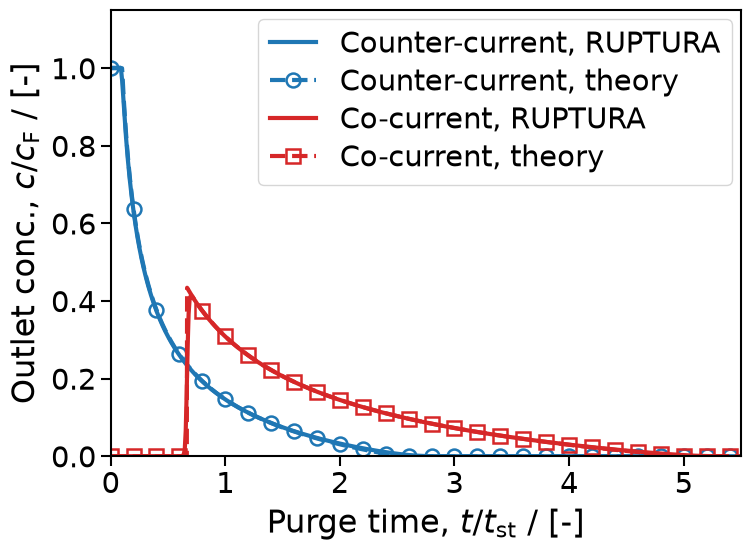

In [5]:
fig, ax = plt.subplots()
for direction, color, marker, label in (("counter-current", "C0", "o", "Counter-current"), ("co-current", "C3", "s", "Co-current")):
    time, concentration = outlet_history(load_run(run_directory(direction)), direction)
    ax.plot(time / STOICHIOMETRIC_TIME, concentration / FEED, color=color, linestyle="-", label=f"{label}, RUPTURA")
    reference_time = np.linspace(0.0, 5.5 * STOICHIOMETRIC_TIME, 2201)
    ax.plot(reference_time / STOICHIOMETRIC_TIME, theory_outlet(direction, reference_time) / FEED, color=color, linestyle="--",
            marker=marker, markerfacecolor="none", markevery=80, label=f"{label}, theory")
ax.set_xlim(0.0, 5.5)
ax.set_ylim(0.0, 1.15)
ax.set_xlabel(r"Purge time, $t/t_\mathrm{st}$ / [-]")
ax.set_ylabel(r"Outlet conc., $c/c_\mathrm{F}$ / [-]")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "flow_reversal_outlet.pdf", dpi=300)
plt.show()

## Column profiles of both purge directions (paper panel b)

The two panels per direction that follow are SI panels.

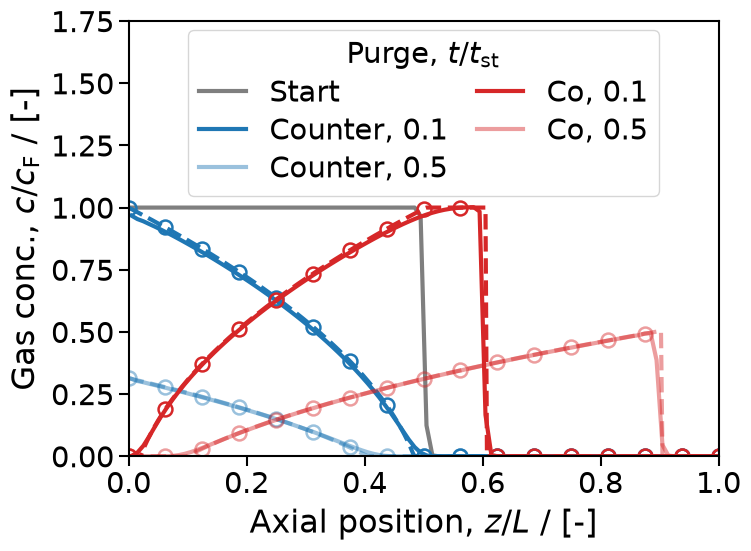

In [6]:
# Paper panel (b): gas-phase profiles of both purge directions in one panel, at the start of the purge and at 0.1 and
# 0.5 stoichiometric times; later profiles are lighter. RUPTURA solid, equilibrium theory dashed with open markers.
fig, ax = plt.subplots()
initial = load_run(run_directory("counter-current"))
start = int(np.argmin(np.abs(initial["time"])))  # the output at the start of the purge
ax.plot(initial["centre"][1:] / LENGTH, initial["c"][start, 1:] / FEED, color="C7", linestyle="-", label="Start")
for direction, color, name in (("counter-current", "C0", "Counter"), ("co-current", "C3", "Co")):
    run = load_run(run_directory(direction))
    for profile_time, alpha in ((0.1, 1.0), (0.5, 0.45)):
        k = int(np.argmin(np.abs(run["time"] - profile_time * STOICHIOMETRIC_TIME)))
        time = run["time"][k]
        ax.plot(run["centre"][1:] / LENGTH, run["c"][k, 1:] / FEED, color=color, alpha=alpha, linestyle="-",
                label=f"{name}, {time / STOICHIOMETRIC_TIME:.1f}")
        position = np.linspace(0.0, LENGTH, 401)
        ax.plot(position / LENGTH, theory_profile(direction, position, time) / FEED, color=color, alpha=alpha,
                linestyle="--", marker="o", markerfacecolor="none", markevery=25)
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.75)
ax.set_xlabel(r"Axial position, $z/L$ / [-]")
ax.set_ylabel(r"Gas conc., $c/c_\mathrm{F}$ / [-]")
ax.legend(loc="upper center", title=r"Purge, $t/t_\mathrm{st}$", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "flow_reversal_profiles.pdf", dpi=300)
plt.show()


## Column profiles, counter-current purge

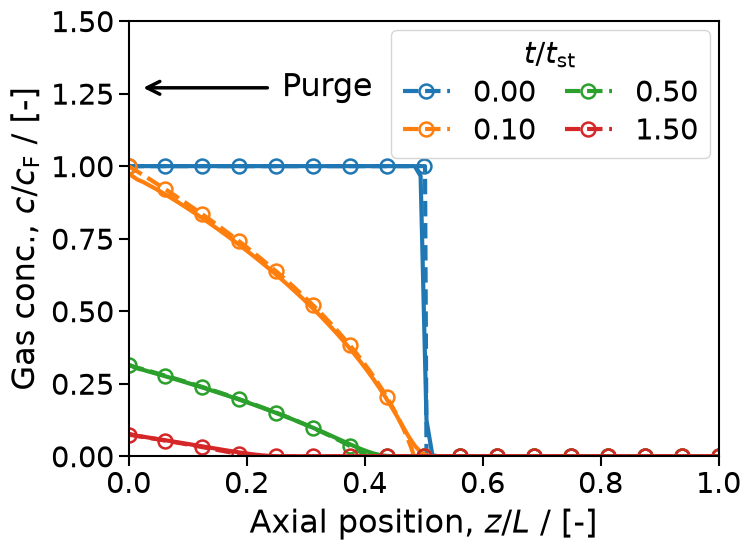

In [7]:
direction = "counter-current"
run = load_run(run_directory(direction))
fig, ax = plt.subplots()
for index, profile_time in enumerate(PROFILE_TIMES):
    k = int(np.argmin(np.abs(run["time"] - profile_time * STOICHIOMETRIC_TIME)))
    time = run["time"][k]
    color = f"C{index}"
    ax.plot(run["centre"][1:] / LENGTH, run["c"][k, 1:] / FEED, color=color, linestyle="-")
    position = np.linspace(0.0, LENGTH, 401)
    ax.plot(position / LENGTH, theory_profile(direction, position, time) / FEED, color=color, linestyle="--", marker="o",
            markerfacecolor="none", markevery=25, label=f"{time / STOICHIOMETRIC_TIME:.2f}")
# RUPTURA solid, equilibrium theory dashed with open markers (caption); the purge enters at z = L
ax.annotate("", xy=(0.02, 1.27), xytext=(0.24, 1.27), arrowprops={"arrowstyle": "->", "lw": 2.5})
ax.text(0.26, 1.27, "Purge", va="center")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.5)
ax.set_xlabel(r"Axial position, $z/L$ / [-]")
ax.set_ylabel(r"Gas conc., $c/c_\mathrm{F}$ / [-]")
ax.legend(loc="upper right", title=r"$t/t_\mathrm{st}$", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "flow_reversal_profiles_counter.pdf", dpi=300)
plt.show()

## Column profiles, co-current purge

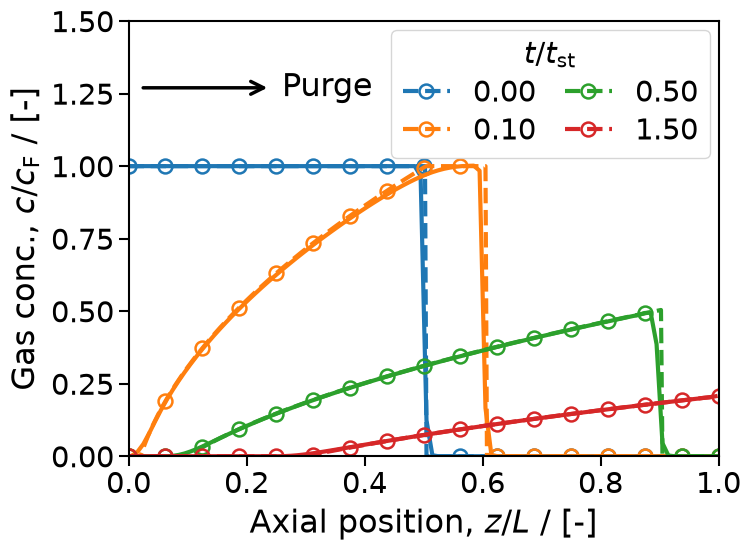

In [8]:
direction = "co-current"
run = load_run(run_directory(direction))
fig, ax = plt.subplots()
for index, profile_time in enumerate(PROFILE_TIMES):
    k = int(np.argmin(np.abs(run["time"] - profile_time * STOICHIOMETRIC_TIME)))
    time = run["time"][k]
    color = f"C{index}"
    ax.plot(run["centre"][1:] / LENGTH, run["c"][k, 1:] / FEED, color=color, linestyle="-")
    position = np.linspace(0.0, LENGTH, 401)
    ax.plot(position / LENGTH, theory_profile(direction, position, time) / FEED, color=color, linestyle="--", marker="o",
            markerfacecolor="none", markevery=25, label=f"{time / STOICHIOMETRIC_TIME:.2f}")
# RUPTURA solid, equilibrium theory dashed with open markers (caption); the purge enters at z = 0
ax.annotate("", xy=(0.24, 1.27), xytext=(0.02, 1.27), arrowprops={"arrowstyle": "->", "lw": 2.5})
ax.text(0.26, 1.27, "Purge", va="center")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.5)
ax.set_xlabel(r"Axial position, $z/L$ / [-]")
ax.set_ylabel(r"Gas conc., $c/c_\mathrm{F}$ / [-]")
ax.legend(loc="upper right", title=r"$t/t_\mathrm{st}$", ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "flow_reversal_profiles_co.pdf", dpi=300)
plt.show()

## Grid convergence of the outlet history

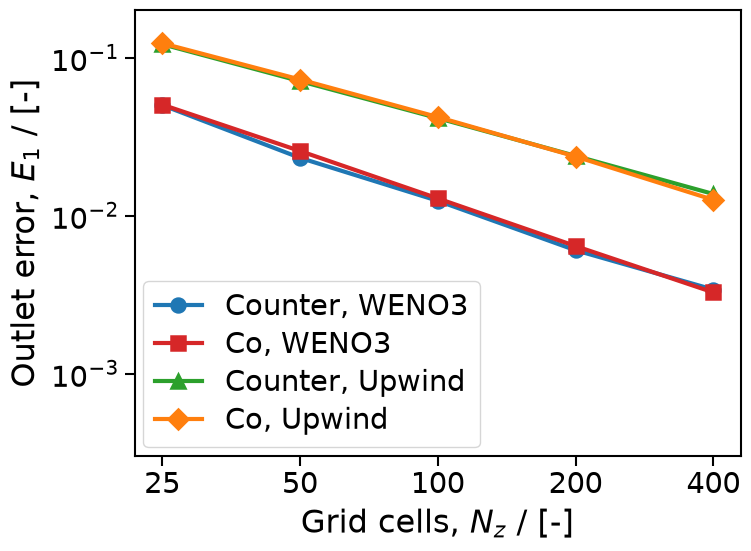

In [9]:
fig, ax = plt.subplots()
for (direction, scheme), color, marker in zip(
        [("counter-current", "WENO3"), ("co-current", "WENO3"), ("counter-current", "Upwind"), ("co-current", "Upwind")],
        ["C0", "C3", "C2", "C1"], ["o", "s", "^", "D"]):
    errors = SUMMARY.loc[(direction, scheme), "outlet_error"]
    ax.plot(errors.index, errors.values, color=color, linestyle="-", marker=marker,
            label=f"{direction.split('-')[0].capitalize()}, {scheme}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([25, 50, 100, 200, 400])
ax.set_xticklabels(["25", "50", "100", "200", "400"])
ax.minorticks_off()
ax.set_ylim(3.0e-4, 2.0e-1)
ax.set_xlabel(r"Grid cells, $N_z$ / [-]")
ax.set_ylabel(r"Outlet error, $E_1$ / [-]")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "flow_reversal_convergence.pdf", dpi=300)
plt.show()

## Amount left in the column during the purge

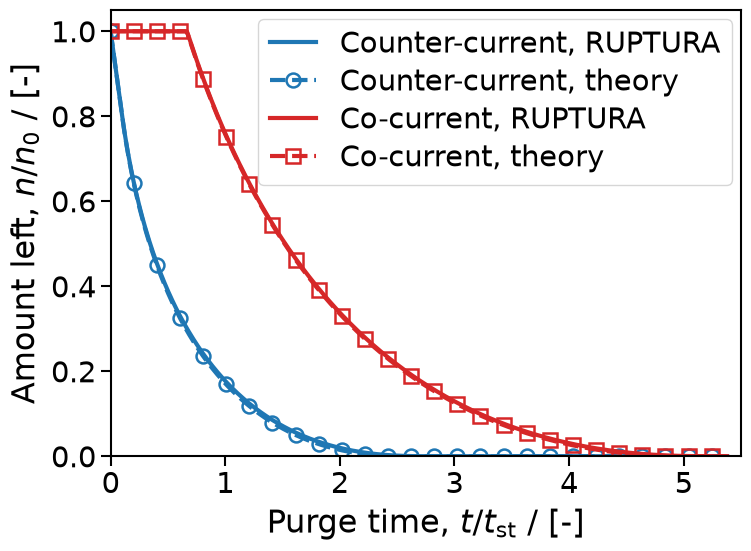

In [10]:
fig, ax = plt.subplots()
for direction, color, marker, label in (("counter-current", "C0", "o", "Counter-current"), ("co-current", "C3", "s", "Co-current")):
    run = load_run(run_directory(direction))
    amount = inventory(run)
    start = int(np.argmin(np.abs(run["time"])))
    purge = run["time"] >= 0.0
    ax.plot(run["time"][purge] / STOICHIOMETRIC_TIME, amount[purge] / amount[start], color=color, linestyle="-",
            label=f"{label}, RUPTURA")
    ax.plot(THEORY_TIME / STOICHIOMETRIC_TIME, THEORY_REMAINING[direction], color=color, linestyle="--", marker=marker,
            markerfacecolor="none", markevery=2400, label=f"{label}, theory")
ax.set_xlim(0.0, 5.5)
ax.set_ylim(0.0, 1.05)
ax.set_xlabel(r"Purge time, $t/t_\mathrm{st}$ / [-]")
ax.set_ylabel(r"Amount left, $n/n_0$ / [-]")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "flow_reversal_inventory.pdf", dpi=300)
plt.show()